In [8]:

!pip install -q streamlit scikit-learn pandas numpy plotly joblib

print("All libraries installed successfully!")


All libraries installed successfully!


In [9]:

import pandas as pd
import numpy as np

np.random.seed(42)

cities = ["Mysore", "Bangalore", "Mandya", "Tumkur",
          "Hassan", "Chennai", "Mangalore", "Coorg"]

rides = pd.DataFrame({
    "ride_id": range(1, 1001),
    "driver": [f"Driver_{i}" for i in np.random.randint(1, 101, 1000)],
    "source": np.random.choice(cities, 1000),
    "destination": np.random.choice(cities, 1000),
    "distance": np.random.randint(20, 500, 1000),
    "duration": np.random.randint(30, 600, 1000),
    "available_seats": np.random.randint(1, 5, 1000),
    "fuel_cost": np.random.randint(90, 111, 1000),
    "toll": np.random.randint(0, 301, 1000)
})

rides = rides[rides["source"] != rides["destination"]].reset_index(drop=True)

rides["fare"] = (
    rides["distance"] * rides["fuel_cost"] / 15 + rides["toll"]
) / (rides["available_seats"] + 1)

rides["fare"] = rides["fare"].round(2)

rides.to_csv("rides.csv", index=False)

print("Dataset generated successfully!")
print("Total rides:", len(rides))
display(rides.head())


Dataset generated successfully!
Total rides: 869


,ride_id,driver,source,destination,distance,duration,available_seats,fuel_cost,toll,fare
0,1,Driver_52,Bangalore,Mysore,133,580,1,96,122,486.60
1,2,Driver_93,Mangalore,Hassan,256,422,3,92,265,458.78
2,3,Driver_15,Coorg,Bangalore,85,236,4,105,28,124.60
3,4,Driver_72,Coorg,Tumkur,380,239,2,107,34,914.89
4,5,Driver_61,Mysore,Mangalore,360,144,4,105,5,505.00


Dataset shape: (869, 10)

Missing values:
ride_id            0
driver             0
source             0
destination        0
distance           0
duration           0
available_seats    0
fuel_cost          0
toll               0
fare               0
dtype: int64

Statistical information:


,ride_id,distance,duration,available_seats,fuel_cost,toll,fare
count,869.000000,869.000000,869.000000,869.000000,869.000000,869.000000,869.000000
mean,501.245109,258.789413,324.224396,2.523590,100.224396,145.263521,593.799321
std,288.863179,139.565077,165.861538,1.115851,5.954633,86.081843,374.074209
min,1.000000,20.000000,30.000000,1.000000,90.000000,0.000000,44.650000
25%,253.000000,137.000000,183.000000,2.000000,95.000000,75.000000,298.070000
50%,504.000000,252.000000,330.000000,3.000000,101.000000,143.000000,544.960000
75%,750.000000,388.000000,467.000000,4.000000,105.000000,217.000000,788.500000
max,1000.000000,498.000000,599.000000,4.000000,110.000000,300.000000,1854.830000


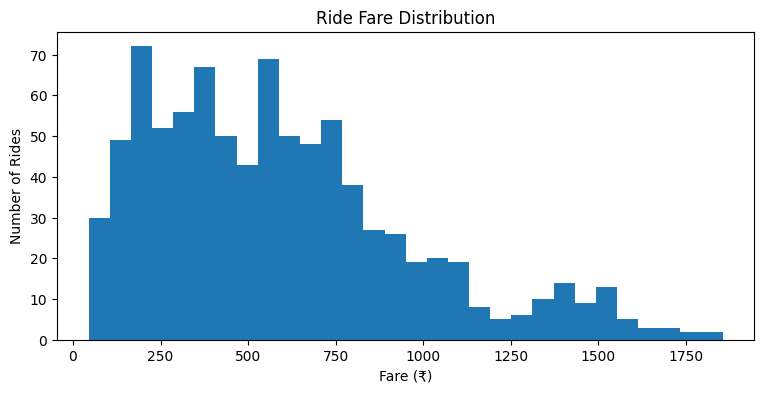

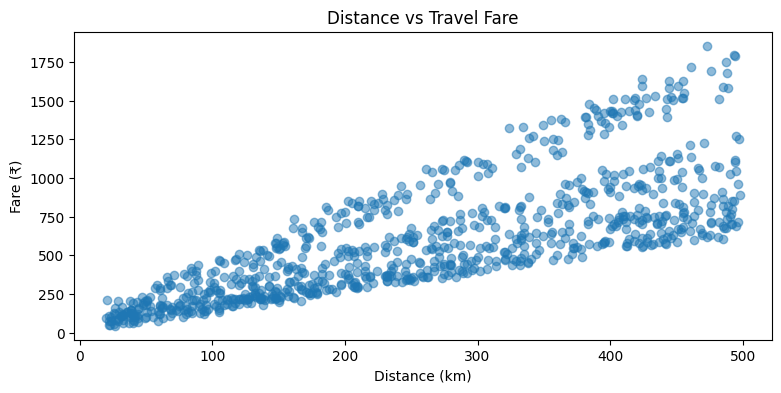

In [10]:

import matplotlib.pyplot as plt

print("Dataset shape:", rides.shape)
print("\nMissing values:")
print(rides.isnull().sum())

print("\nStatistical information:")
display(rides.describe())

plt.figure(figsize=(9, 4))
plt.hist(rides["fare"], bins=30)
plt.title("Ride Fare Distribution")
plt.xlabel("Fare (₹)")
plt.ylabel("Number of Rides")
plt.show()

plt.figure(figsize=(9, 4))
plt.scatter(rides["distance"], rides["fare"], alpha=0.5)
plt.title("Distance vs Travel Fare")
plt.xlabel("Distance (km)")
plt.ylabel("Fare (₹)")
plt.show()


In [11]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import numpy as np

features = [
    "distance", "duration", "available_seats",
    "fuel_cost", "toll"
]

X = rides[features]
y = rides["fare"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("R2 Score:", round(r2_score(y_test, predictions), 3))
print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2))

joblib.dump(model, "rideshare_model.pkl")

print("ML model trained successfully!")


R2 Score: 0.993
MAE: 25.11
RMSE: 33.72
ML model trained successfully!


In [27]:

import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd
import plotly.express as px
import joblib

# Load project data
rides = pd.read_csv("rides.csv")
bookings = pd.DataFrame(
    columns=["booking_id", "ride_id", "passenger", "seats", "status"]
)

model = joblib.load("rideshare_model.pkl")

cities = [
    "Mysore", "Bangalore", "Mandya", "Tumkur",
    "Hassan", "Chennai", "Mangalore", "Coorg"
]

next_ride_id = int(rides["ride_id"].max()) + 1
next_booking_id = 1

# Main output area
out = widgets.Output()

# Input widgets
driver = widgets.Text(description="Driver:")
ride_from = widgets.Dropdown(options=cities, description="From:")
ride_to = widgets.Dropdown(options=cities, description="To:")
distance = widgets.IntSlider(value=150, min=20, max=1000, description="KM:")
duration = widgets.IntSlider(value=180, min=30, max=1000, description="Minutes:")
seats = widgets.IntSlider(value=3, min=1, max=7, description="Seats:")
fuel = widgets.IntSlider(value=105, min=50, max=150, description="Fuel ₹:")
toll = widgets.IntSlider(value=100, min=0, max=1000, description="Toll ₹")

passenger = widgets.Text(description="Passenger:")
search_from = widgets.Dropdown(options=cities, description="From:")
search_to = widgets.Dropdown(options=cities, description="To:")
search_seats = widgets.IntSlider(value=1, min=1, max=7, description="Seats:")

fare_distance = widgets.IntSlider(value=150, min=20, max=1000, description="KM:")
fare_duration = widgets.IntSlider(value=180, min=30, max=1000, description="Minutes:")
fare_seats = widgets.IntSlider(value=3, min=1, max=7, description="Seats:")
fare_fuel = widgets.IntSlider(value=105, min=50, max=150, description="Fuel ₹:")
fare_toll = widgets.IntSlider(value=100, min=0, max=1000, description="Toll ₹:")

ride_select = widgets.Dropdown(description="Ride ID:")
booking_select = widgets.Dropdown(description="Booking ID:")

# Buttons
offer_btn = widgets.Button(description="Publish Ride", button_style="success")
search_btn = widgets.Button(description="Search Rides", button_style="info")
book_btn = widgets.Button(description="Request Booking", button_style="success")
manage_btn = widgets.Button(description="Approve Booking", button_style="success")
reject_btn = widgets.Button(description="Reject Booking", button_style="danger")
predict_btn = widgets.Button(description="Predict Fare", button_style="info")
dashboard_btn = widgets.Button(description="Refresh Dashboard")

def show_dashboard():
    with out:
        clear_output(wait=True)
        print("🚗 RIDESHARE AI DASHBOARD")
        print("=" * 45)
        print("Total Rides:", len(rides))
        print("Available Seats:", int(rides["available_seats"].sum()))
        print("Total Bookings:", len(bookings))
        print("\nRecent Rides:")
        display(rides.tail(10))

def offer_ride(b):
    global rides, next_ride_id

    if not driver.value.strip():
        with out:
            clear_output()
            print("Please enter driver name.")
        return

    if ride_from.value == ride_to.value:
        with out:
            clear_output()
            print("Choose different starting and destination cities.")
        return

    fare = (distance.value * fuel.value / 15 + toll.value) / (seats.value + 1)

    new_ride = pd.DataFrame([{
        "ride_id": next_ride_id,
        "driver": driver.value,
        "source": ride_from.value,
        "destination": ride_to.value,
        "distance": distance.value,
        "duration": duration.value,
        "available_seats": seats.value,
        "fuel_cost": fuel.value,
        "toll": toll.value,
        "fare": round(fare, 2)
    }])

    rides = pd.concat([rides, new_ride], ignore_index=True)
    rides.to_csv("rides.csv", index=False)
    next_ride_id += 1

    with out:
        clear_output()
        print("✅ Ride published successfully!")
        display(new_ride)

def search_rides(b):
    with out:
        clear_output()

        if not passenger.value.strip():
            print("Please enter passenger name.")
            return

        if search_from.value == search_to.value:
            print("Choose different locations.")
            return

        result = rides[
            (rides["source"] == search_from.value) &
            (rides["destination"] == search_to.value) &
            (rides["available_seats"] >= search_seats.value)
        ]

        if result.empty:
            print("No matching rides found.")
            ride_select.options = []
        else:
            print("✅ Matching rides found:")
            display(result)
            ride_select.options = result["ride_id"].tolist()

def request_booking(b):
    global bookings, next_booking_id

    if ride_select.value is None:
        with out:
            clear_output()
            print("Search and select a ride first.")
        return

    ride_id = ride_select.value
    available = rides.loc[
        rides["ride_id"] == ride_id, "available_seats"
    ].iloc[0]

    if search_seats.value > available:
        with out:
            clear_output()
            print("Not enough available seats.")
        return

    new_booking = pd.DataFrame([{
        "booking_id": next_booking_id,
        "ride_id": ride_id,
        "passenger": passenger.value,
        "seats": search_seats.value,
        "status": "Pending"
    }])

    bookings = pd.concat([bookings, new_booking], ignore_index=True)
    bookings.to_csv("bookings.csv", index=False)
    next_booking_id += 1

    with out:
        clear_output()
        print("✅ Booking request submitted!")
        display(new_booking)

def update_booking(approve=True):
    global rides, bookings

    if booking_select.value is None:
        with out:
            clear_output()
            print("No booking selected.")
        return

    idx = bookings.index[
        bookings["booking_id"] == booking_select.value
    ][0]

    booking = bookings.loc[idx]

    if booking["status"] != "Pending":
        with out:
            clear_output()
            print("This booking has already been processed.")
        return

    if approve:
        ride_idx = rides.index[
            rides["ride_id"] == booking["ride_id"]
        ][0]

        remaining = int(rides.loc[ride_idx, "available_seats"])

        if booking["seats"] > remaining:
            with out:
                clear_output()
                print("Not enough seats remaining.")
            return

        rides.loc[ride_idx, "available_seats"] = (
            remaining - int(booking["seats"])
        )
        bookings.loc[idx, "status"] = "Approved"
        message = "✅ Booking approved!"
    else:
        bookings.loc[idx, "status"] = "Rejected"
        message = "❌ Booking rejected!"

    rides.to_csv("rides.csv", index=False)
    bookings.to_csv("bookings.csv", index=False)

    with out:
        clear_output()
        print(message)
        display(bookings)

def refresh_bookings():
    pending = bookings[bookings["status"] == "Pending"]
    booking_select.options = pending["booking_id"].tolist()

def manage_approve(b):
    update_booking(True)
    refresh_bookings()

def manage_reject(b):
    update_booking(False)
    refresh_bookings()

def predict_fare(b):
    data = pd.DataFrame([{
        "distance": fare_distance.value,
        "duration": fare_duration.value,
        "available_seats": fare_seats.value,
        "fuel_cost": fare_fuel.value,
        "toll": fare_toll.value
    }])

    prediction = model.predict(data)[0]

    with out:
        clear_output()
        print("🧠 MACHINE LEARNING FARE PREDICTION")
        print("=" * 40)
        print(f"Estimated Travel Fare: ₹{prediction:.2f}")

def show_analytics():
    with out:
        clear_output()
        print("📊 RIDE ANALYTICS")
        print("Average Fare: ₹", round(rides["fare"].mean(), 2))

        fig = px.bar(
            rides.groupby("source").size().reset_index(name="rides"),
            x="source", y="rides",
            color="rides", title="Rides by Starting Location"
        )
        fig.show()

        fig2 = px.scatter(
            rides, x="distance", y="fare",
            color="available_seats",
            title="Distance vs Fare"
        )
        fig2.show()

offer_btn.on_click(offer_ride)
search_btn.on_click(search_rides)
book_btn.on_click(request_booking)
manage_btn.on_click(manage_approve)
reject_btn.on_click(manage_reject)
predict_btn.on_click(predict_fare)
dashboard_btn.on_click(lambda b: show_dashboard())

# Create notebook tabs
tabs = widgets.Tab()
tabs.children = [
    widgets.VBox([dashboard_btn]),
    widgets.VBox([
        driver, ride_from, ride_to, distance,
        duration, seats, fuel, toll, offer_btn
    ]),
    widgets.VBox([
        passenger, search_from, search_to,
        search_seats, search_btn, ride_select, book_btn
    ]),
    widgets.VBox([
        booking_select, manage_btn, reject_btn
    ]),
    widgets.VBox([
        fare_distance, fare_duration, fare_seats,
        fare_fuel, fare_toll, predict_btn
    ]),
    widgets.VBox([
        widgets.Button(description="Show Analytics",
                       on_click=lambda b: show_analytics())
    ])
]

for i, name in enumerate([
    "Dashboard", "Offer a Ride", "Find a Ride",
    "Bookings", "Fare Prediction", "Analytics"
]):
    tabs.set_title(i, name)

display(widgets.HTML(
    "<h1 style='color:#2563eb'>🚗 RideShare AI</h1>"
    "<p>Smart Carpooling and Travel Cost Optimization System</p>"
))
display(tabs)
display(out)

show_dashboard()


HTML(value="<h1 style='color:#2563eb'>🚗 RideShare AI</h1><p>Smart Carpooling and Travel Cost Optimization Syst…

Output()

In [29]:

def search_rides(b):
    with out:
        clear_output(wait=True)

        if not passenger.value.strip():
            print("⚠️ Please enter passenger name.")
            return

        if search_from.value == search_to.value:
            print("⚠️ Select different locations.")
            return

        result = rides[
            (rides["source"] == search_from.value) &
            (rides["destination"] == search_to.value) &
            (rides["available_seats"] >= search_seats.value)
        ].copy()

        if result.empty:
            ride_select.options = []
            print("❌ No matching rides found.")
            return

        # Populate Ride ID dropdown
        ride_select.options = [
            (f"Ride {int(row.ride_id)} | {row.driver} | ₹{row.fare:.2f}",
             int(row.ride_id))
            for row in result.itertuples()
        ]

        ride_select.value = int(result.iloc[0]["ride_id"])

        print("✅ Matching rides found!")
        display(result)
        print("\nSelect your Ride ID from the dropdown below.")


In [30]:

from IPython.display import display, clear_output

# Display the dashboard tabs
display(tabs)

# Display the output area
display(out)

# Load the dashboard
with out:
    clear_output(wait=True)
    show_dashboard()


Output()